# Can Moons Survive in Tightly Packed Planetary Systems?

*Matthew Payne*

Many of the multi-planet systems found by Kepler are *Systems with Tightly-packed Inner Planets* (STIPs): neighbouring planets whose orbits are separated by only a few tens of percent. When two such planets pass each other, they come within a few of their Hill radii. Could a moon survive around one of them, or would the neighbour's repeated close passages strip it away?

This notebook repeats, at a smaller scale, the numerical experiments of

> M. J. Payne, K. M. Deck, M. J. Holman & H. B. Perets (2013), *Stability of Satellites in Closely Packed Planetary Systems*, ApJL **775**, L44. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...775L..44P/abstract) · [arXiv:1308.4402](https://arxiv.org/abs/1308.4402)

(PDHP13). We will:

1. Recall the stability limit for a moon around a single planet: about half the Hill radius for prograde moons (Domingos et al. 2006).
2. Take PDHP13's two-planet systems, packed as closely as stability allows, and add a lunar-mass moon to the outer planet.
3. Map which moon orbits survive, prograde and retrograde, and compare with PDHP13's approximate new boundary.
4. Relate the damage to how close the two planets come to each other.

**Requirements:** `numpy`, `matplotlib` and `rebound`. **Run time:** the moon integrations take about 20 minutes on 12 cores and are cached in `cache/`, so the notebook normally runs in seconds. Set `RECOMPUTE = True` to redo them, or `QUICK = True` for a smaller version (a few minutes).

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np

import stips    # helper module in this folder

QUICK = False          # True: 150 moons per configuration for 100 orbits (a few minutes)
RECOMPUTE = False      # True: ignore cached results and integrate again
NPROC = os.cpu_count()
N_MOONS = 150 if QUICK else 600       # per configuration (PDHP13 used 10^4)
N_ORBITS = 100 if QUICK else 300      # planetary orbits integrated (PDHP13: 3,000)
CACHE = "cache_quick" if QUICK else "cache"
os.makedirs(CACHE, exist_ok=True)
rng = np.random.default_rng(13)

## 1. The set-up

A moon of the Moon's mass orbits the outer planet, which is on a circular orbit at 1 au around a solar-mass star. Distances are measured in the parent planet's Hill radius, $R_{H} = a\,(m/3)^{1/3}$ with $m$ its mass in units of the star's. Around a *single* planet, Domingos et al. (2006) found prograde moons stable out to $a_{\max}/R_H = 0.49\,(1 - 1.03\,e_{\rm p} - 0.27\,e_{\rm sat})$, and retrograde moons out to $0.93\,(1 - 1.08\,e_{\rm p} - 0.98\,e_{\rm sat})$ (PDHP13 Secs. 3.1 and 3.3).

PDHP13 chose their two-planet systems from the stability maps of Deck, Payne & Holman (2013) (the subject of the resonance-overlap notebook in this collection): equal-mass pairs as closely spaced as possible while still stable. We use five of their sets (Sec. 2.1), drawing each system's period ratio and inner-planet eccentricity from the set's range:

| set | planet masses | period ratio $P_2/P_1$ | inner eccentricity |
|---|---|---|---|
| C | $10^{-4}$ (≈ 2 Uranus masses) | 1.130 – 1.136 | 0.012 – 0.015 |
| D | $10^{-4}$ | 1.187 – 1.192 | 0.095 – 0.100 |
| E | $10^{-4}$ | 1.31 – 1.35 | 0 – 0.01 |
| F | $10^{-3}$ (≈ Jupiter) | 1.28 – 1.30 | 0.095 – 0.100 |
| G | $10^{-3}$ | 1.49 – 1.51 | 0.095 – 0.100 |

Each moon starts with semi-major axis and eccentricity drawn uniformly (prograde: 0.1–0.6 $R_H$; retrograde: 0.1–0.99 $R_H$; eccentricity 0–1) and its other orbital elements zero, as in PDHP13. PDHP13 integrated $10^4$ moons per set for 3,000 planetary orbits and mapped Lyapunov times; we integrate 600 per set for 300 orbits with IAS15 and record simply whether the moon is still bound inside the parent's Hill sphere at the end. Our maps therefore show the moons that are lost quickly, not the slower chaos that PDHP13's Lyapunov times also reveal, and we start at 0.1 $R_H$ rather than 0.01 $R_H$, since nothing happens close in.

In [2]:
def run_set(name, retro, pool):
    lo, hi = (0.1, 0.99) if retro else (0.1, 0.6)
    a = rng.uniform(lo, hi, N_MOONS)
    e = rng.uniform(0, 1, N_MOONS)
    jobs = [(name, a[k], e[k], retro, N_ORBITS, 1000 + k) for k in range(N_MOONS)]
    res = pool.map(stips.moon_run, jobs, chunksize=4)
    return dict(a=a, e=e, ok=np.array([r[0] for r in res]), dmin=np.array([r[1] for r in res]))

configs = [("single", False), ("C", False), ("D", False), ("E", False), ("F", False), ("G", False),
           ("single", True), ("E", True), ("G", True)]
path = os.path.join(CACHE, f"moons_{N_MOONS}_{N_ORBITS}.npz")
results = {}
if os.path.exists(path) and not RECOMPUTE:
    z = np.load(path)
    results = {(name, retro): {k: z[f"{name}_{int(retro)}_{k}"] for k in ("a", "e", "ok", "dmin")} for name, retro in configs}
else:
    t0 = time.time()
    with Pool(NPROC) as pool:
        for name, retro in configs:
            results[(name, retro)] = run_set(name, retro, pool)
    np.savez_compressed(path, **{f"{name}_{int(retro)}_{k}": v for (name, retro), r in results.items() for k, v in r.items()})
    print(f"({time.time() - t0:.0f} s)")
for name, retro in configs:
    r = results[(name, retro)]
    print(f"{name:6s} {'retrograde' if retro else 'prograde  '}: {r['ok'].mean():5.1%} of moons survive {N_ORBITS} orbits")

single prograde  : 65.3% of moons survive 300 orbits
C      prograde  : 59.0% of moons survive 300 orbits
D      prograde  : 56.5% of moons survive 300 orbits
E      prograde  : 63.0% of moons survive 300 orbits
F      prograde  : 55.5% of moons survive 300 orbits
G      prograde  : 60.0% of moons survive 300 orbits
single retrograde: 53.5% of moons survive 300 orbits
E      retrograde: 54.5% of moons survive 300 orbits
G      retrograde: 45.8% of moons survive 300 orbits


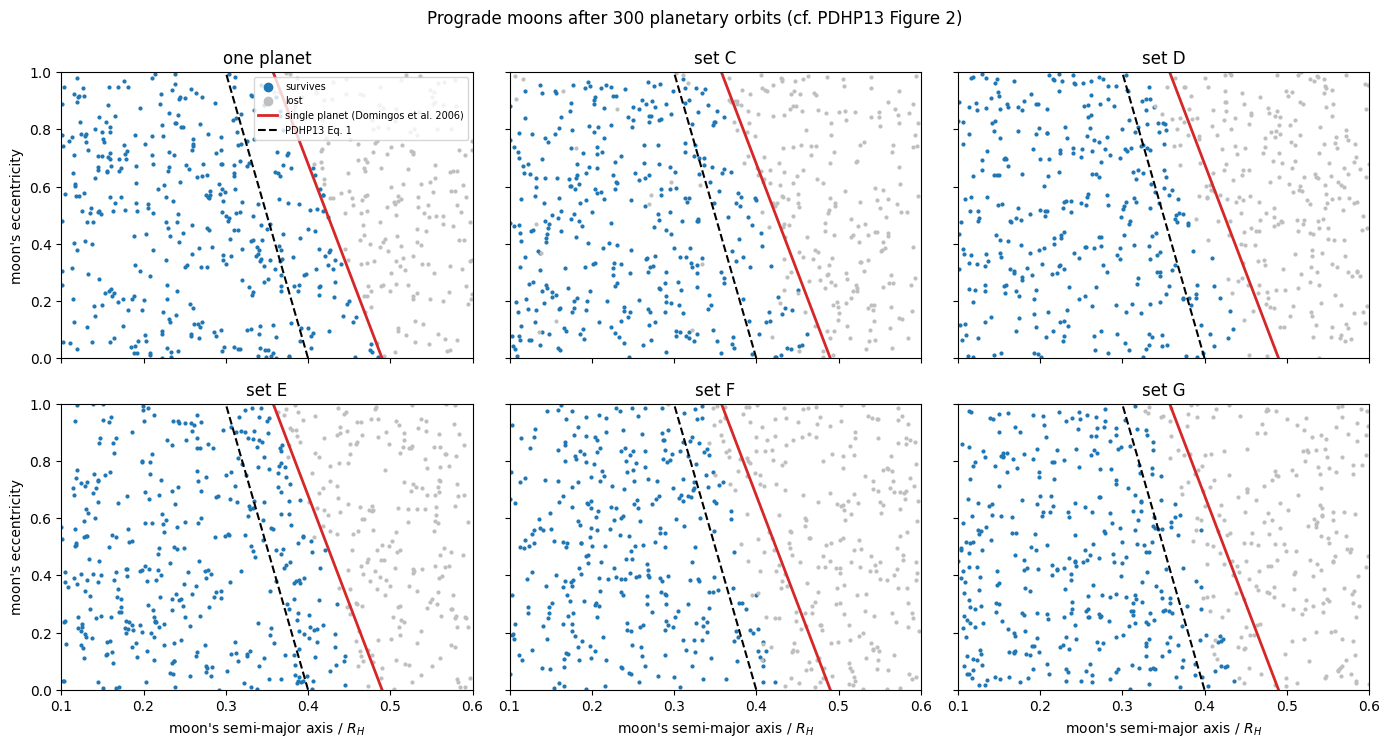

In [3]:
ee = np.linspace(0, 1, 50)
fig, axs = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, name in zip(axs.ravel(), ["single", "C", "D", "E", "F", "G"]):
    r = results[(name, False)]
    ax.scatter(r["a"][r["ok"]], r["e"][r["ok"]], s=4, color="C0", label="survives")
    ax.scatter(r["a"][~r["ok"]], r["e"][~r["ok"]], s=4, color="0.75", label="lost")
    ax.plot(stips.boundary_d06(ee), ee, color="C3", lw=2, label="single planet (Domingos et al. 2006)")
    ax.plot(stips.boundary_pdhp13(ee), ee, "--", color="k", lw=1.5, label="PDHP13 Eq. 1")
    title = "one planet" if name == "single" else f"set {name}"
    ax.set(title=title, xlim=(0.1, 0.6), ylim=(0, 1))
for ax in axs[-1]:
    ax.set_xlabel("moon's semi-major axis / $R_H$")
for ax in axs[:, 0]:
    ax.set_ylabel("moon's eccentricity")
axs[0, 0].legend(fontsize=7, loc="upper right", markerscale=3)
fig.suptitle(f"Prograde moons after {N_ORBITS} planetary orbits (cf. PDHP13 Figure 2)", y=0.99)
fig.tight_layout()
plt.show()

Around a single planet (top left), the surviving moons stop at the Domingos et al. boundary, as they should: the red line separates the survivors from the lost moons. A close neighbour moves the edge inwards. In sets C, D, F and G it lies near PDHP13's approximate boundary (dashed), about $0.4\,R_H$ for circular moon orbits, roughly $0.1\,R_H$ inside the single-planet limit. In set E the edge stays close to the single-planet line for moons on near-circular orbits. Everywhere, moons well inside the edge survive: the neighbour removes only the outermost moons. This is what PDHP13 found (their Sec. 3.2): in every stable two-planet set the boundary moved inwards by up to $0.1\,R_H$, by different amounts in different sets, which is why they called their Eq. 1 "extremely approximate".

Our maps show only moons that are lost within 300 orbits. PDHP13's Lyapunov times also reveal chaotic moons just inside the edge, which survive their 3,000 orbits but would probably not survive indefinitely; a longer integration would move our edge inwards a little.

## 2. Retrograde moons

Retrograde moons are stable much further out around a single planet, almost to the Hill radius. PDHP13 (Sec. 3.3) found that a close neighbour cuts this back for systems whose planets approach within about 4 mutual Hill radii, to around $0.6\,R_H$, while systems with more distant approaches keep moons nearly as far out as a single planet.

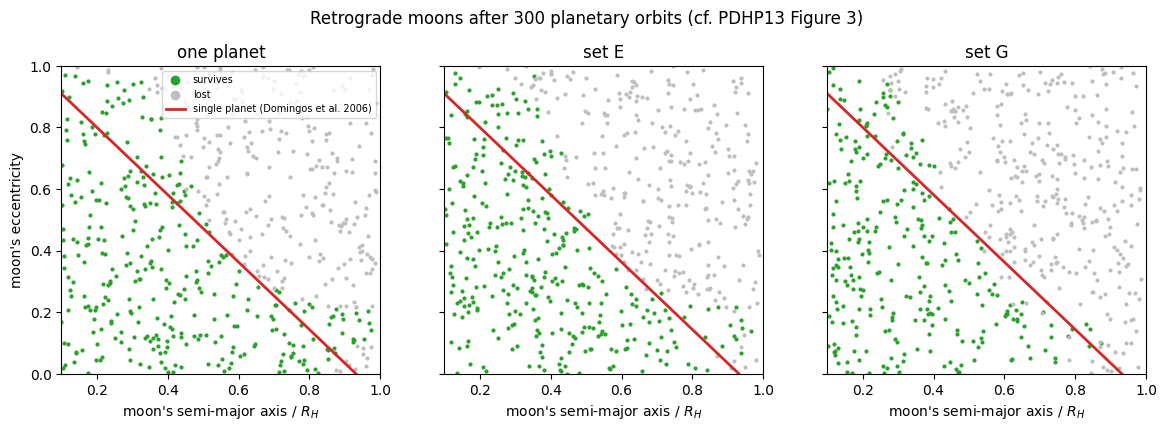

Closest planet-planet approach without a moon (median of 3 systems, 100 orbits), in mutual Hill radii:
   set C: 2.4
   set D: 5.1
   set E: 4.8
   set F: 2.9
   set G: 4.0


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, name in zip(axs, ["single", "E", "G"]):
    r = results[(name, True)]
    ax.scatter(r["a"][r["ok"]], r["e"][r["ok"]], s=4, color="C2", label="survives")
    ax.scatter(r["a"][~r["ok"]], r["e"][~r["ok"]], s=4, color="0.75", label="lost")
    ax.plot(stips.boundary_d06(ee, retro=True), ee, color="C3", lw=2, label="single planet (Domingos et al. 2006)")
    ax.set(title="one planet" if name == "single" else f"set {name}", xlim=(0.1, 1.0), ylim=(0, 1), xlabel="moon's semi-major axis / $R_H$")
axs[0].set_ylabel("moon's eccentricity")
axs[0].legend(fontsize=7, markerscale=3)
fig.suptitle(f"Retrograde moons after {N_ORBITS} planetary orbits (cf. PDHP13 Figure 3)", y=1.02)
plt.show()

closest = {n: np.median([stips.planets_only_closest(n, 100, s) for s in range(3)]) for n in ["C", "D", "E", "F", "G"]}
print("Closest planet-planet approach without a moon (median of 3 systems, 100 orbits), in mutual Hill radii:")
for n, d in closest.items():
    print(f"   set {n}: {d:.1f}")

Around a single planet, retrograde moons survive out to the Domingos et al. line, and at high eccentricities slightly beyond it: PDHP13 noted the same, in a region Domingos et al. did not explore. With a neighbour, the closest approach of the two planets matters. Set E's planets stay about 5 mutual Hill radii apart, and its retrograde moons survive almost as far out as around a single planet, approaching $0.9\,R_H$ on near-circular orbits. Set G's planets come within about 4 mutual Hill radii, and its moons are cut back to about $0.6\,R_H$. PDHP13 (Sec. 3.3) found the same division: sets whose planets approach within about 4 mutual Hill radii (C, F, G) support retrograde moons only out to about $0.6\,R_H$, and the others (D, E) nearly as far out as a single planet. Our closest approaches place the sets on the same sides of that line, with G right at it.

## Summary

* Around a single planet, our integrations reproduce the known limits: prograde moons out to about half the Hill radius, retrograde moons almost to the Hill radius (Domingos et al. 2006).
* A neighbouring planet, even one packed as closely as stability allows, removes only the outermost moons. The prograde limit moves inwards by up to about $0.1\,R_H$, close to PDHP13's approximate boundary $0.4\,(1 - e_{\rm sat}/4)\,R_H$.
* For retrograde moons, the dividing line is how close the planets come: within about 4 mutual Hill radii, the limit falls to about $0.6\,R_H$; beyond that, it is almost unchanged.
* So tightly packed planets can keep moons, provided the moons orbit well inside the Hill sphere, as the large moons of the Solar System do (the Moon is at about a quarter of the Earth's Hill radius, the Galilean moons within a twentieth of Jupiter's).
* These are small versions of PDHP13's experiments (600 moons per set rather than $10^4$, and 300 orbits rather than 3,000), measuring survival rather than chaos, so the edges are a little fuzzier and slightly further out than theirs.

## Going further

* **Lyapunov times.** Surviving 300 orbits is not the same as being stable. REBOUND can integrate the variational equations and compute the MEGNO chaos indicator; mapping it, as PDHP13 mapped Lyapunov times, reveals the chaotic but still-bound moons near the boundary.
* **Sets A and B.** PDHP13's most tightly packed sets, of planets of about three Earth masses, were destabilised by the moon itself: the moon's small pull was enough to tip the planets into close encounters.
* **Tides.** Neither tides nor the planet's oblateness are modelled. PDHP13 note that tidal migration can remove moons on longer timescales, and that a reduced stable zone speeds this up.

## References

* Deck, K. M., Payne, M. & Holman, M. J. 2013, *First-order Resonance Overlap and the Stability of Close Two-planet Systems*, ApJ 774, 129. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...774..129D/abstract)
* Domingos, R. C., Winter, O. C. & Yokoyama, T. 2006, *Stable satellites around extrasolar giant planets*, MNRAS 373, 1227. [ADS](https://ui.adsabs.harvard.edu/abs/2006MNRAS.373.1227D/abstract)
* Payne, M. J., Deck, K. M., Holman, M. J. & Perets, H. B. 2013, *Stability of Satellites in Closely Packed Planetary Systems*, ApJL 775, L44. [ADS](https://ui.adsabs.harvard.edu/abs/2013ApJ...775L..44P/abstract)
* Rein, H. & Spiegel, D. S. 2015, *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics, accurate to machine precision over a billion orbits*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)